# Circumstellar Habitable Zones

Plot the Teff/Seff plane for the [Kopparapu et al. 2014, ApJL, 787, L29](https://ui.adsabs.harvard.edu/abs/2014ApJ...787L..29K/abstract) conservative and optimistic habitable 
zones.

Codes the polynomial functions defined in Eqn 4 and the coefficients in Table 1.

Another set of plots use data from Table 8 of [Bryson et al. 2021, AJ, 161, 36](https://ui.adsabs.harvard.edu/abs/2021AJ....161...36B/abstract) to plot the data for Kepler DR25 habitable zone candidates.

In [3]:
%matplotlib inline

import math
import numpy as np

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, LogLocator, NullFormatter

from astropy.io import ascii

import warnings
warnings.filterwarnings('ignore',category=UserWarning, append=True)

## Standard Plot Format

Setup the standard plotting format and make the plots.  Style is similar to that used by the ISM/IGM book

In [4]:
# graphic aspect ratio = width/height

aspect = 4.0/3.0

# Text width in inches - don't change, this is defined by the print layout

textWidth = 6.0 # inches

# output format and resolution

figFmt = 'png'
dpi = 600

# Graphic dimensions 

plotWidth = dpi*textWidth
plotHeight = plotWidth/aspect
axisFontSize = 14
labelFontSize = 10
lwidth = 0.5
axisPad = 5
wInches = textWidth 
hInches = wInches/aspect

# LaTeX is used throughout for markup of symbols, Times-Roman serif font

plt.rc('text', usetex=True)
plt.rc('font', **{'family':'serif','serif':['Times-Roman'],'weight':'bold','size':'16'})

# Font and line weight defaults for axes

matplotlib.rc('axes',linewidth=lwidth)
matplotlib.rcParams.update({'font.size':axisFontSize})

# axis and label padding

plt.rcParams['xtick.major.pad'] = f'{axisPad}'
plt.rcParams['ytick.major.pad'] = f'{axisPad}'
plt.rcParams['axes.labelpad'] = f'{axisPad}'

## Kopparapu et al. habitable zones

The parametric equations to calculate HZs are given in Kopparapu et al. Equation 4:
\begin{equation}
   S_{eff} = S_{eff,\odot} + aT_* + bT_*^2 + cT_*^3 + dT_*^4
\end{equation}
where:
\begin{equation}
   T_* = T_{eff} - 5780K
\end{equation}

Corresponding habitable zone distances are given by Kopparapu et al. Equation 5:
\begin{equation}
   d_{au} = \left(\frac{L/L_{\odot}}{S_{eff}}\right)^{0.5}
\end{equation}

There is a light dependence of $S_{eff,\odot}$ on planetary mass, but for this notebook we will
only use the values from Kopparapu et al. Table 1 for 1 earth mass.

The "conservative" habitable zone is bounded by the "runaway greenhouse" (inner) and "maximum greenhouse" (outer)
zones, whereas the "optimistic" habitable zone bounds are the "recent Venus" and "early Mars" zones.

We code this for using numpy poly1d, so order of coefficients is (d,c,b,a,S_eff).

Dictionary keywords:
 * innerOpt = inner optimistic habitable zone (recent Venus)
 * innerCon = inner conservative habitable zone (runaway greenhouse)
 * outerCon = outer conservative habitable zone (maximum greenhouse)
 * outerOpt = outer optimistics habitable zone (early Mars)

In [5]:
# Contents of Kopparapu et al. 2014 Table 1, M_earth, as separate dictionaries

optSsun = {'innerOpt':1.776,'innerCon':1.107,'outerCon':0.356,'outerOpt':0.32}

a = {'innerOpt':2.136e-4,'innerCon':1.332e-4,'outerCon':6.171e-5,'outerOpt':5.547e-5}
b = {'innerOpt':2.533e-8,'innerCon':1.58e-8,'outerCon':1.698e-9,'outerOpt':1.526e-9}
c = {'innerOpt':-1.332e-11,'innerCon':-8.308e-12,'outerCon':-3.198e-12,'outerOpt':-2.874e-12}
d = {'innerOpt':-3.097e-15,'innerCon':-1.931e-15,'outerCon':-5.57e-16,'outerOpt':-5.011e-16}

# polynomial list dictionary for numpy.poly1d

hzPoly = {'innerOpt': [-3.097e-15,-1.332e-11,2.533e-8,2.136e-4,1.776],
          'innerCon': [-1.931e-15,-8.308e-12,1.580e-8,1.332e-4,1.107],
          'outerCon': [-5.575e-16,-3.198e-12,1.698e-9,6.171e-5,0.356],
          'outerOpt': [-5.011e-16,-2.874e-12,1.526e-9,5.547e-5,0.320]}

zones = ['innerOpt','outerOpt','innerCon','outerCon']

## example base plot

For stellar T<sub>eff</sub> from 3800 to 7200K, plot installation flux (S<sub>eff</sub>/S<sub>eff,sun</sub>)
on X axis and T<sub>eff</sub> on the Y axis

In [6]:
minT = 3850.0 # rounded off Mamajek M0V 3850K
maxT = 7220.0 # Mamajek F0V

Teff = np.linspace(minT,maxT,num=101)

S_earth = {}

for zone in zones:
    p = np.poly1d(hzPoly[zone])
    S_earth[zone] = np.polyval(p,(Teff-5780))

# Range runs backwards, higher instellation is closer to star

minS = 2.3
maxS = 0.0

6.0x4.5-inches @ 600-dpi


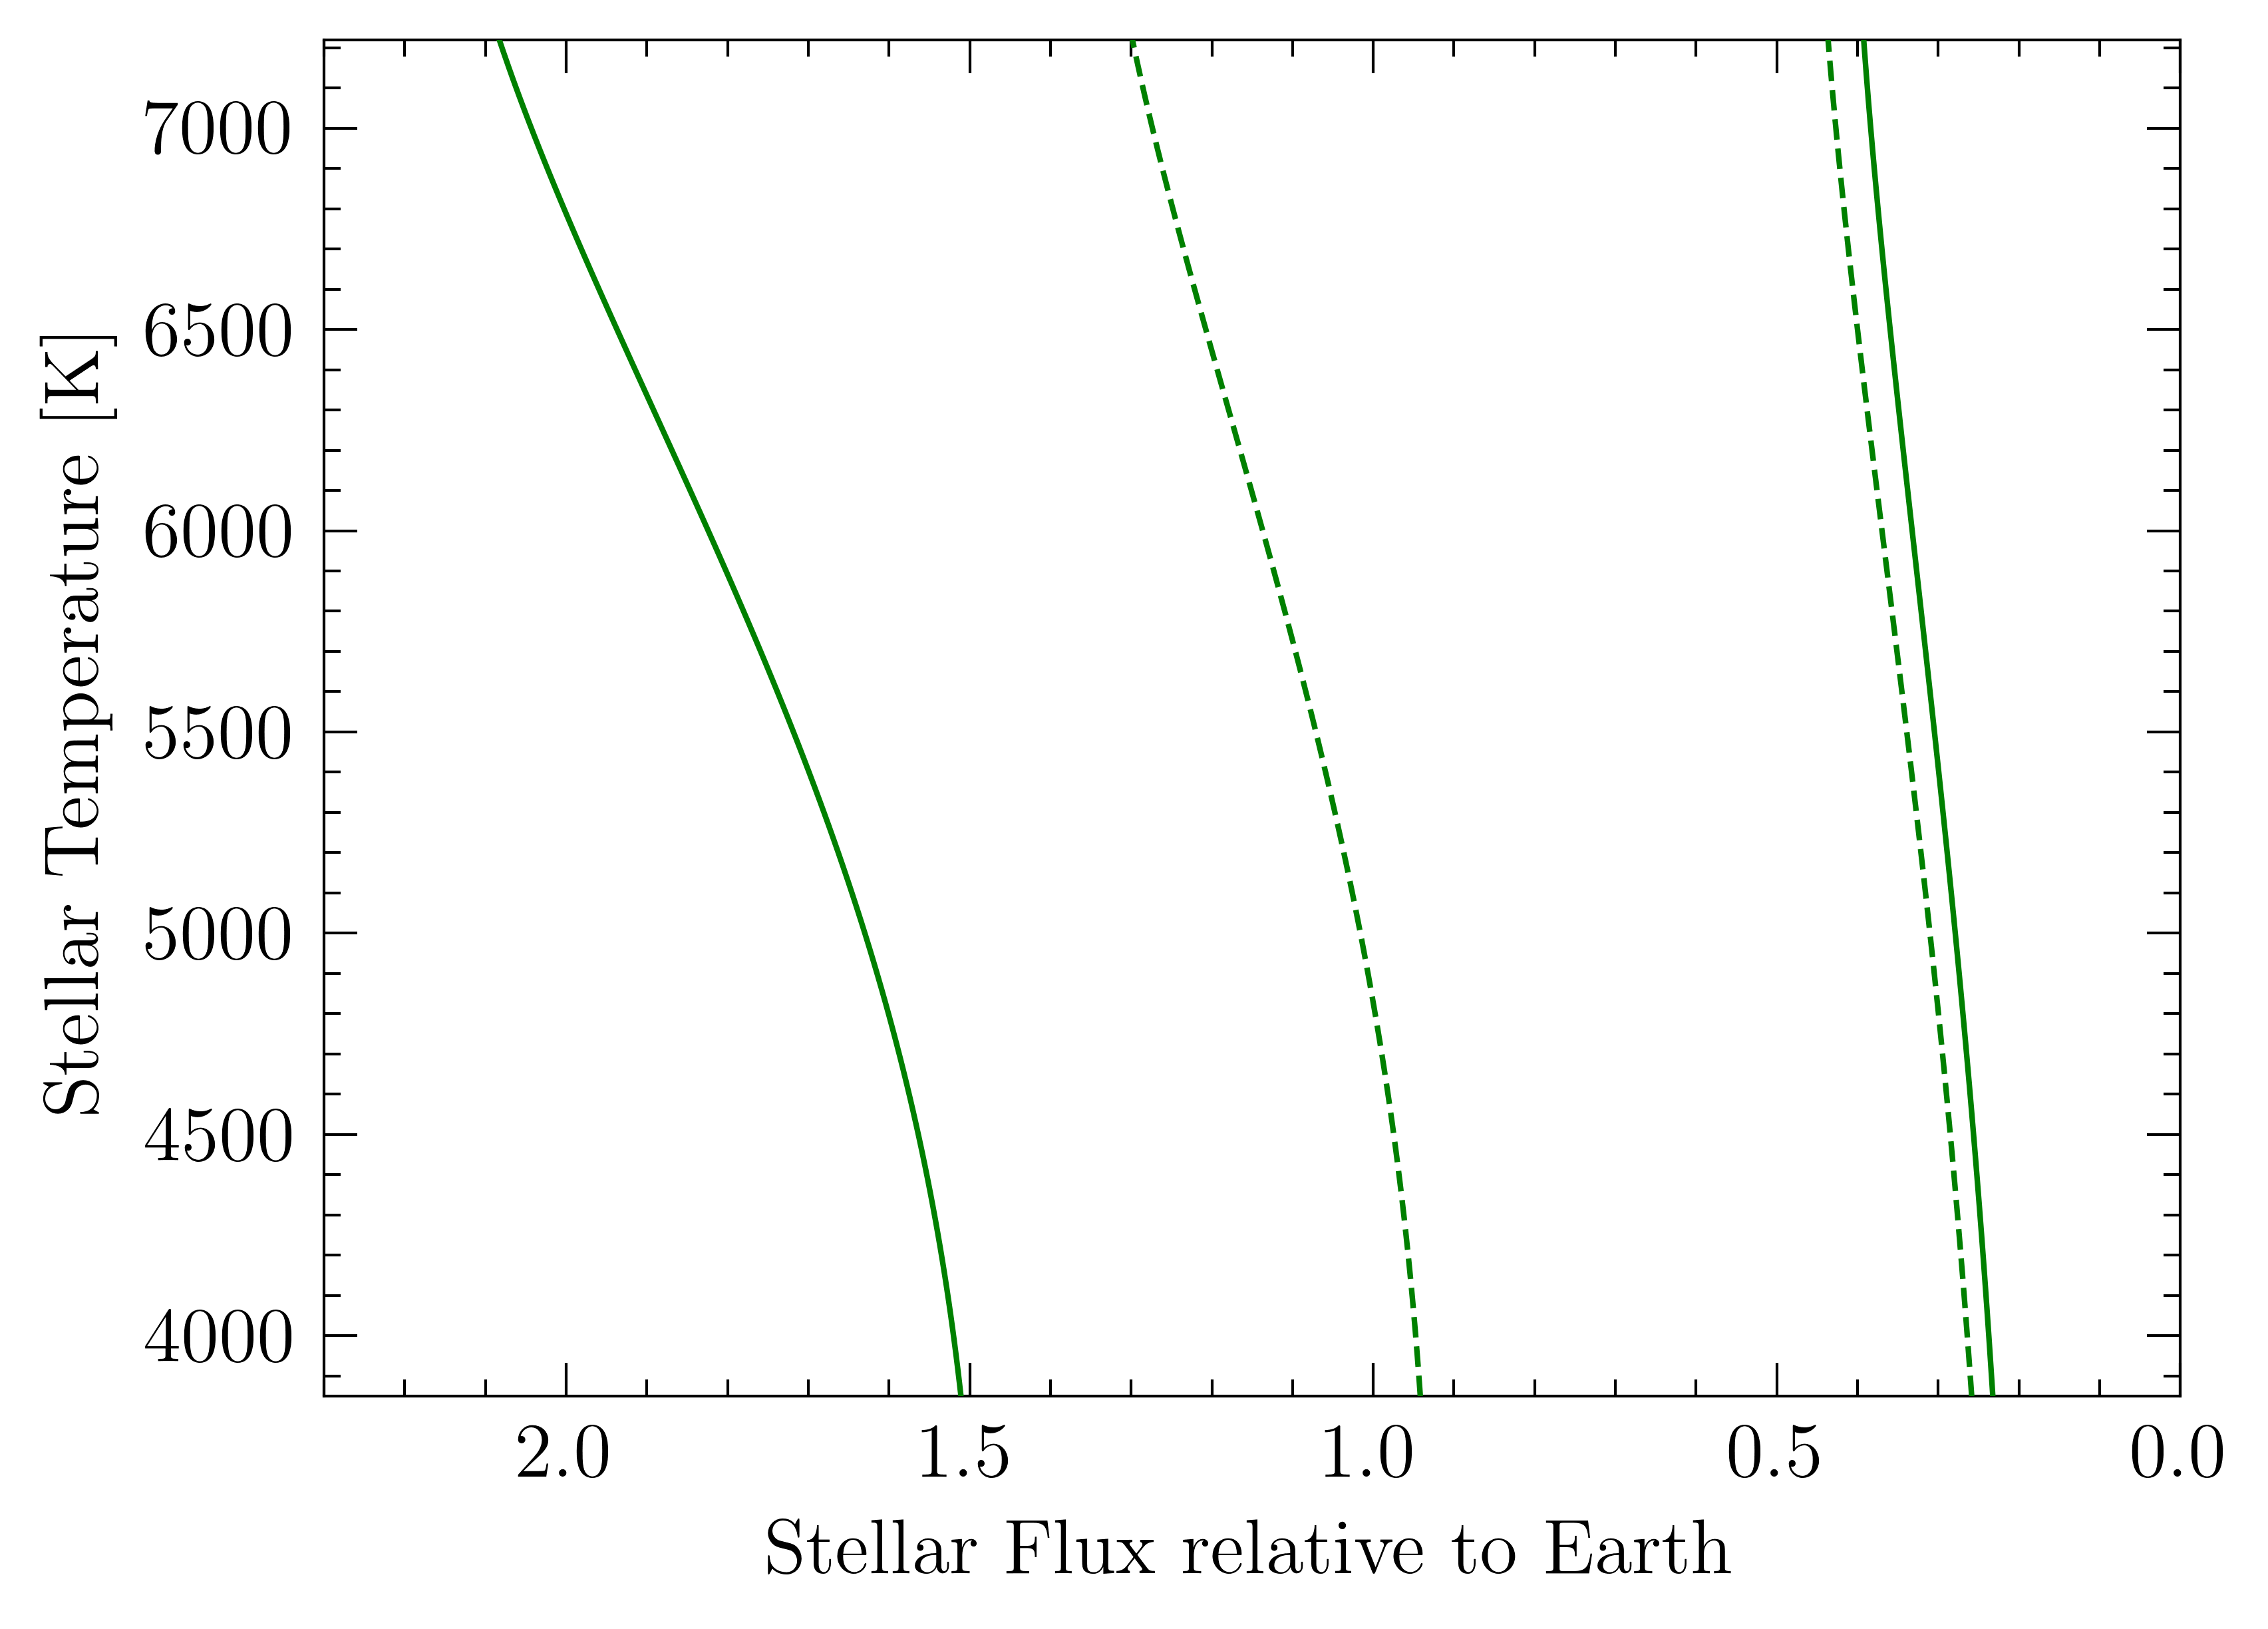

In [7]:
plotFile = f'HZ_plot.{figFmt}'

fig,ax = plt.subplots(figsize=(wInches,hInches),dpi=dpi)

print(f'{wInches:.1f}x{hInches:.1f}-inches @ {dpi}-dpi')
# Axes

ax.tick_params('both',length=6,width=lwidth,which='major',direction='in',top='on',right='on')
ax.tick_params('both',length=3,width=lwidth,which='minor',direction='in',top='on',right='on')

plt.xlim(minS,maxS)
ax.xaxis.set_major_locator(MultipleLocator(0.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
plt.xlabel(r'Stellar Flux relative to Earth')

plt.ylim(minT,maxT)
ax.yaxis.set_major_locator(MultipleLocator(500))
ax.yaxis.set_minor_locator(MultipleLocator(100))
plt.ylabel(r'Stellar Temperature [K]')

# Plot the total and individual cooling functions

plt.plot(S_earth['innerOpt'],Teff,'-',color='green',lw=1,zorder=10)
plt.plot(S_earth['innerCon'],Teff,'--',color='green',lw=1,zorder=10)
plt.plot(S_earth['outerCon'],Teff,'--',color='green',lw=1,zorder=10)
plt.plot(S_earth['outerOpt'],Teff,'-',color='green',lw=1,zorder=10)

# make the figure

plt.plot()
plt.savefig(plotFile,bbox_inches='tight',facecolor='white')

## Fancier Example: Bryson et al 2021 Kepler HZ planets

Use data from Table 8 of Bryson et al. 2021, AJ, 161, 36 to plot the data for Kepler DR25 habitable zone
candidates

N(habitable)=8
N<=2.5*R_E = 54


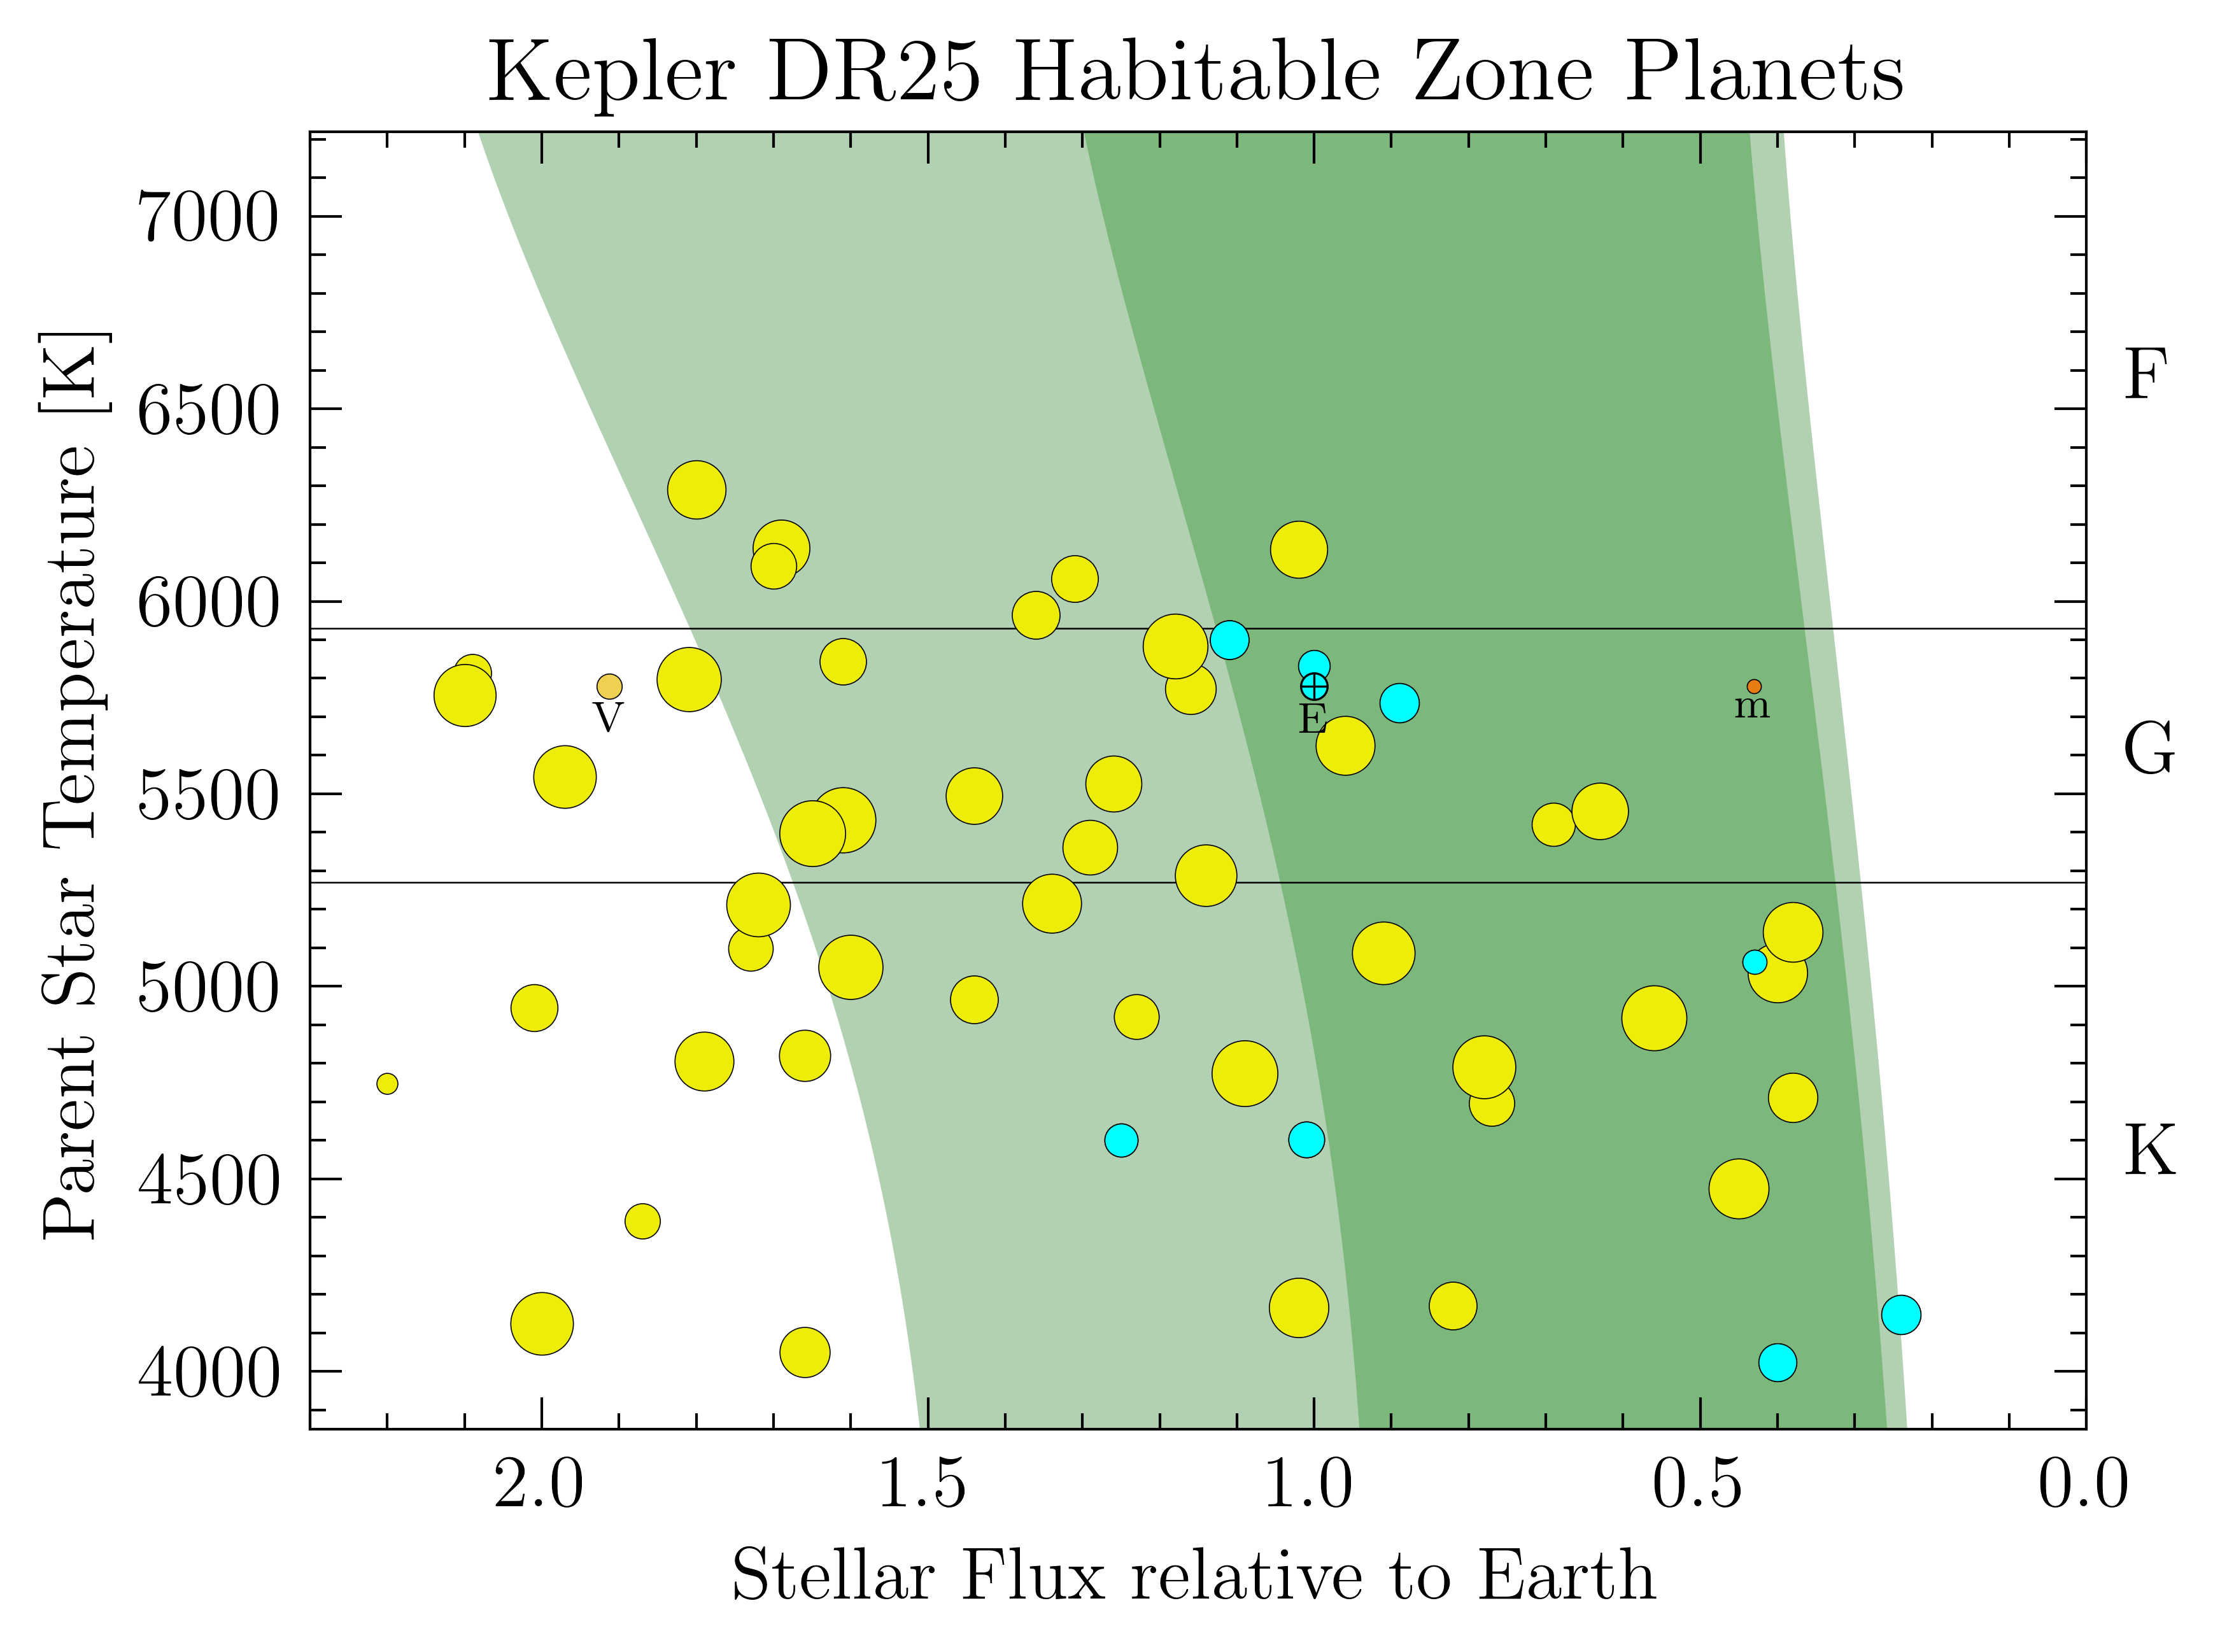

In [8]:
tabFile = 'Bryson2021_Table8.txt'
plotFile = f'HZ_plot_exoEarths.{figFmt}'

tabData = ascii.read(tabFile,format='cds')

# marker size for R=R_earth

msE = 5.0

#print(tabData)

minRad = 0.5 # R_earth
maxRad = 1.5 

radE = np.array(tabData['Radius'].tolist())
msP = msE*radE
starT = np.array(tabData['Teff'].tolist())
instel = np.array(tabData['Instel'].tolist())

p = np.poly1d(hzPoly['innerOpt'])
S_inner = np.polyval(p,(starT-5780))
    
parentTeff = []
planetIe = []
msPlanet = []

for i in range(len(radE)):
    if radE[i]>=minRad and radE[i]<=maxRad:
        if instel[i]<= S_inner[i]:
            parentTeff.append(starT[i])
            planetIe.append(instel[i])
            msPlanet.append(msP[i])

print(f'N(habitable)={len(parentTeff)}')

fig,ax = plt.subplots(figsize=(wInches,hInches),dpi=dpi)

# Axes

ax.tick_params('both',length=6,width=lwidth,which='major',direction='in',top='on',right='on')
ax.tick_params('both',length=3,width=lwidth,which='minor',direction='in',top='on',right='on')

plt.xlim(minS,maxS)
ax.xaxis.set_major_locator(MultipleLocator(0.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
plt.xlabel(r'Stellar Flux relative to Earth')

plt.ylim(minT,maxT)
ax.yaxis.set_major_locator(MultipleLocator(500))
ax.yaxis.set_minor_locator(MultipleLocator(100))
plt.ylabel(r'Parent Star Temperature [K]')

# Plot the candidate HZ planets - pale yellow = #eeed09 general, cyan for HZP etaEarth

for i in range(len(parentTeff)):
    plt.plot(planetIe[i],parentTeff[i],'o',ms=msPlanet[i],mfc='cyan',mec='black',mew=0.2,zorder=10)

# Plot all candidates (alt color: light orange = #fed8b1 or pale yellow = #eeed09)

pCount = 0
for i in range(len(starT)):
    if radE[i]<=2.5 and radE[i]>=0.5:
        plt.plot(instel[i],starT[i],'o',ms=msP[i],mfc='#eeed09',mec='black',mew=0.2,zorder=5)
        pCount += 1
        
print(f'N<=2.5*R_E = {pCount}')

# Earth

plt.plot(1.0,5780,'o',ms=msE,mfc='cyan',mec='black',mew=0.4,zorder=10)
plt.plot(1.0,5780,'+',ms=msE,color='black',mew=0.4,zorder=10)
plt.text(1.0,5735,'E',color='black',va='top',ha='center',fontsize=8,zorder=10)

# Venus

aVenus = 0.723
iVenus = 1.0/(aVenus*aVenus)
plt.plot(iVenus,5780,'o',ms=msE*0.9499,mfc='#eed053',mec='black',mew=0.2,zorder=10)
plt.text(iVenus,5735,'V',color='black',va='top',ha='center',fontsize=8,zorder=10)

# Mars

aMars = 1.524
iMars = 1.0/(aMars*aMars)
plt.plot(iMars,5780,'o',ms=msE*0.533,mfc='#e77d11',mec='black',mew=0.2,zorder=10)
plt.text(iMars,5775,'m',color='black',va='top',ha='center',fontsize=8,zorder=10)

# Bryson et al. Teff limits for eta-Earth

#plt.hlines(4800,minS,maxS,ls='--',color='black',lw=0.5)
#plt.hlines(6300,minS,maxS,ls='--',color='black',lw=0.5)

# Spectra type dividing lines, based on Mamajek 2021

spTeff = {'F0V':7220,'F9V':5990,'G0V':5930,'G9V':5380,'K0V':5270,'K9V':3930,'M0V':3850}

plt.hlines(spTeff['G0V'],minS,maxS,ls='-',color='black',zorder=5,lw=0.3)
plt.hlines(spTeff['K0V'],minS,maxS,ls='-',color='black',zorder=5,lw=0.3)

plt.text(maxS-0.05,0.5*(spTeff['F0V']+spTeff['G0V']),'F',color='black',ha='left',va='center',fontsize=14)
plt.text(maxS-0.05,0.5*(spTeff['G0V']+spTeff['K0V']),'G',color='black',ha='left',va='center',fontsize=14)
plt.text(maxS-0.05,0.5*(spTeff['M0V']+spTeff['K0V']),'K',color='black',ha='left',va='center',fontsize=14)


# Plot the total and individual cooling functions

#plt.plot(S_earth['innerOpt'],Teff,'--',color='green',lw=0.5,zorder=9)
#plt.plot(S_earth['outerOpt'],Teff,'--',color='green',lw=0.5,zorder=9)
plt.fill_betweenx(Teff,S_earth['innerOpt'],S_earth['outerOpt'],color='darkgreen',alpha=0.3,lw=0)

#plt.plot(S_earth['innerCon'],Teff,'-',color='green',lw=0.5,zorder=9)
#plt.plot(S_earth['outerCon'],Teff,'-',color='green',lw=0.5,zorder=9)
plt.fill_betweenx(Teff,S_earth['innerCon'],S_earth['outerCon'],color='green',alpha=0.3,lw=0)

# make the figure

plt.title('Kepler DR25 Habitable Zone Planets')

plt.plot()
plt.savefig(plotFile,bbox_inches='tight',facecolor='white')      

## Bryson et al. without FGK (intro-astro lite version)

Use data from Table 8 of Bryson et al. 2021, AJ, 161, 36 to plot the data for Kepler DR25 habitable zone
candidates, but omits the FGK star divisions

N(habitable)=8
N<=2.5*R_E = 54


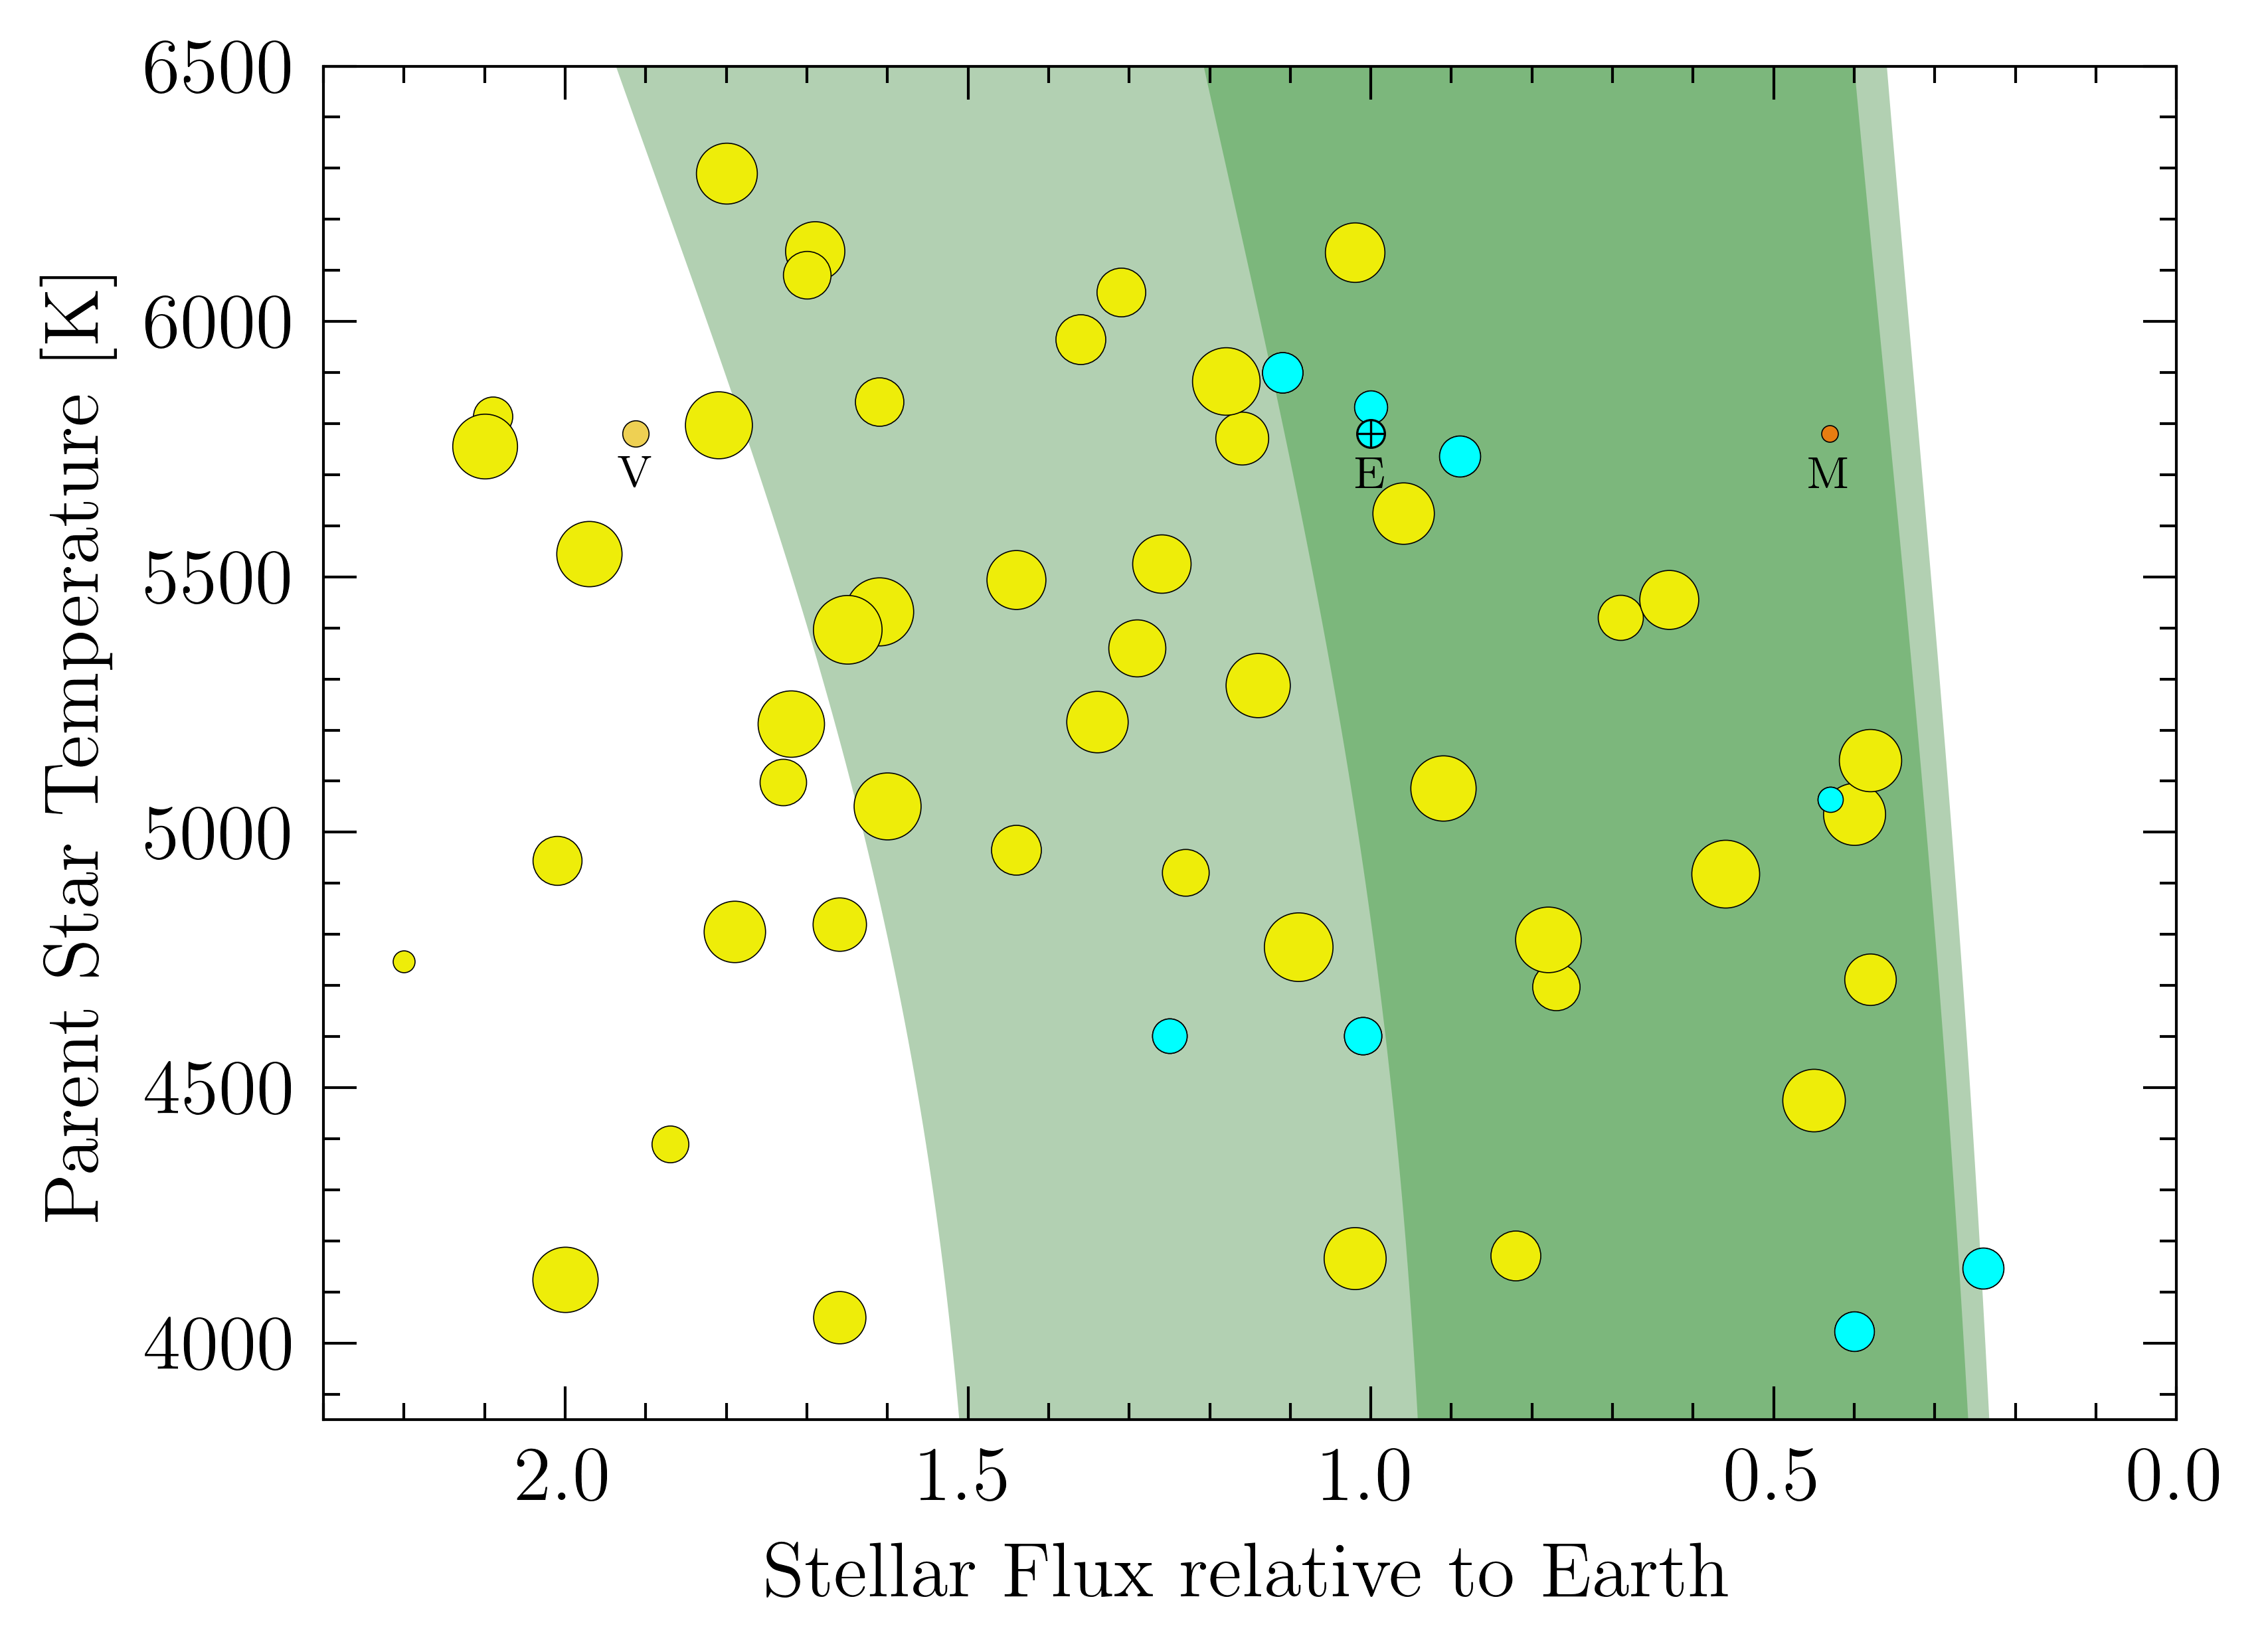

In [15]:
tabFile = 'Bryson2021_Table8.txt'
plotFile = f'HZ_plot_exoEarths_simple.{figFmt}'

tabData = ascii.read(tabFile,format='cds')

# for this plot, max out at Teff=6500

maxT = 6500.

# marker size for R=R_earth

msE = 5.0

#print(tabData)

minRad = 0.5 # R_earth
maxRad = 1.5 

radE = np.array(tabData['Radius'].tolist())
msP = msE*radE
starT = np.array(tabData['Teff'].tolist())
instel = np.array(tabData['Instel'].tolist())

p = np.poly1d(hzPoly['innerOpt'])
S_inner = np.polyval(p,(starT-5780))
    
parentTeff = []
planetIe = []
msPlanet = []

for i in range(len(radE)):
    if radE[i]>=minRad and radE[i]<=maxRad:
        if instel[i]<= S_inner[i]:
            parentTeff.append(starT[i])
            planetIe.append(instel[i])
            msPlanet.append(msP[i])

print(f'N(habitable)={len(parentTeff)}')

fig,ax = plt.subplots(figsize=(wInches,hInches),dpi=dpi)

# Axes

ax.tick_params('both',length=6,width=lwidth,which='major',direction='in',top='on',right='on')
ax.tick_params('both',length=3,width=lwidth,which='minor',direction='in',top='on',right='on')

plt.xlim(minS,maxS)
ax.xaxis.set_major_locator(MultipleLocator(0.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
plt.xlabel(r'Stellar Flux relative to Earth')

plt.ylim(minT,maxT)
ax.yaxis.set_major_locator(MultipleLocator(500))
ax.yaxis.set_minor_locator(MultipleLocator(100))
plt.ylabel(r'Parent Star Temperature [K]')

# Plot the candidate HZ planets - pale yellow = #eeed09 general, cyan for HZP etaEarth

for i in range(len(parentTeff)):
    plt.plot(planetIe[i],parentTeff[i],'o',ms=msPlanet[i],mfc='cyan',mec='black',mew=0.2,zorder=10)

# Plot all candidates (alt color: light orange = #fed8b1 or pale yellow = #eeed09)

pCount = 0
for i in range(len(starT)):
    if radE[i]<=2.5 and radE[i]>=0.5:
        plt.plot(instel[i],starT[i],'o',ms=msP[i],mfc='#eeed09',mec='black',mew=0.2,zorder=5)
        pCount += 1
        
print(f'N<=2.5*R_E = {pCount}')

# Earth

plt.plot(1.0,5780,'o',ms=msE,mfc='cyan',mec='black',mew=0.4,zorder=10)
plt.plot(1.0,5780,'+',ms=msE,color='black',mew=0.4,zorder=10)
plt.text(1.0,5735,'E',color='black',va='top',ha='center',fontsize=8,zorder=10)

# Venus

aVenus = 0.723
iVenus = 1.0/(aVenus*aVenus)
plt.plot(iVenus,5780,'o',ms=msE*0.9499,mfc='#eed053',mec='black',mew=0.2,zorder=10)
plt.text(iVenus,5735,'V',color='black',va='top',ha='center',fontsize=8,zorder=10)

# Mars

aMars = 1.524
iMars = 1.0/(aMars*aMars)
plt.plot(iMars,5780,'o',ms=msE*0.6,mfc='#e77d11',mec='black',mew=0.2,zorder=10)
plt.text(iMars,5735,'M',color='black',va='top',ha='center',fontsize=8,zorder=10)

# Plot the total and individual cooling functions

plt.fill_betweenx(Teff,S_earth['innerOpt'],S_earth['outerOpt'],color='darkgreen',alpha=0.3,lw=0)
plt.fill_betweenx(Teff,S_earth['innerCon'],S_earth['outerCon'],color='green',alpha=0.3,lw=0)

# make the figure

#plt.title('Kepler DR25 Habitable Zone Planets')

plt.plot()
plt.savefig(plotFile,bbox_inches='tight',facecolor='white')      